# Absorption v2 — Threshold & Parameter Analysis

**Three modes** — run any cell independently:

| Cell | What it produces |
|------|------------------|
| **Cell A** | Per-instrument heatmap (z_delta × z_price grid) + score distribution |
| **Cell B** | Per-structure pooled heatmap (all instruments in spread / jumbo combined) |
| **Cell C** | Per-instrument absorption_score threshold sweep table (Precision/Recall/F1/MCC) |

All three share the same labeling trick:
- Score every bar with `calculate_absorption_v2` (dummy thresholds so z_delta/z_price are computed everywhere)
- Run `label_absorption_atr` **twice** (once forcing BUY, once forcing SELL)
- Apply actual thresholds as masks at query time — **no re-labeling per threshold**

In [1]:
import sys
from pathlib import Path
import numpy as np

project_root = r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from market_analysis.finding_threshold.absorption_v2_threshold import (
    run_heatmap_analysis,
    run_heatmap_by_structure,
    run_threshold_sweep,
)
from market_analysis.signals.absorption.calculate_rolling import (
    calculate_absorption_rolling,
)
print('Imports OK')

Imports OK


## Shared Parameters
Edit once here — all cells below read from these variables.

In [2]:
# ── what to analyse ───────────────────────────────────────────────────────────
PRODUCT_CODE  = "SM"    # "SM" or "BO"
MONTHS_BACK   = 8       # calendar months of OHLC history to fetch
FRONT_N       = 5       # front-N spreads + front-N jumbos
COMBINED_CANDLE = 3    # 1 = standard 1D  |  2 = 2D rolling  |  3 = 3D  |  5 = 5D

# ── heatmap threshold grids ───────────────────────────────────────────────────
# X-axis: minimum |z_delta| required (higher = rarer, stronger signal)
DELTA_Z_GRID  = np.arange(1.0, 3.25, 0.25)

# Y-axis: maximum z_price allowed
# z_price measures MAGNITUDE of price move (it is based on abs(close-prev_close))
# Lower z_price = smaller-than-usual price move = stronger absorption
PRICE_Z_GRID  = np.arange(0.5, -1.75, -0.25)

# ── scorer params (v2 windows) ────────────────────────────────────────────────
V2_PARAMS = {
    "volume_window"   : 5,    # rolling avg volume lookback for delta normalisation
    "atr_window"      : 5,    # ATR lookback for price normalisation
    "baseline_window" : 15,   # median/MAD z-score baseline window
    # labeler
    "atr_period"      : 14,   # ATR period for stop/target levels
    "target_atr_mult" : 1.5,  # target = close ± ATR × this
    "stop_atr_mult"   : 1.5,  # stop   = close ∓ ATR × this
    "forward_days"    : 10,   # max days to scan forward for outcome
    # dummy thresholds — DO NOT change unless you want to pre-filter direction
    # setting these to 0 / 9999 means every bar gets z_delta and z_price computed
    "delta_z_threshold": 0,
    "price_z_threshold": 9999,
}

# ── sweep table params ────────────────────────────────────────────────────────
SCORE_GRID        = np.round(np.arange(0.05, 1.0, 0.05), 3)
MIN_SIGNAL_COUNT  = 8     # N < this is highlighted yellow in the table
N_BOOTSTRAP       = 500   # bootstrap resamples for Precision CI
RANDOM_SEED       = 42

print(f"Product : {PRODUCT_CODE}")
print(f"delta_z_grid : {DELTA_Z_GRID}")
print(f"price_z_grid : {PRICE_Z_GRID}")

Product : SM
delta_z_grid : [1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.  ]
price_z_grid : [ 0.5   0.25  0.   -0.25 -0.5  -0.75 -1.   -1.25 -1.5 ]


## Cell A — Per-Instrument Heatmap + Score Distribution

For each instrument:
1. **Heatmap** — success rate at every (Δz threshold, Pz threshold) combination. Annotations show S/F/N counts and mean absorption_score.
2. **Distribution** — success vs failure histogram of the continuous `absorption_score`.


########################################################################
#  STRUCTURE : SPREAD  —  SM  [3D rolling]
########################################################################

──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMV26-Z26  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 185


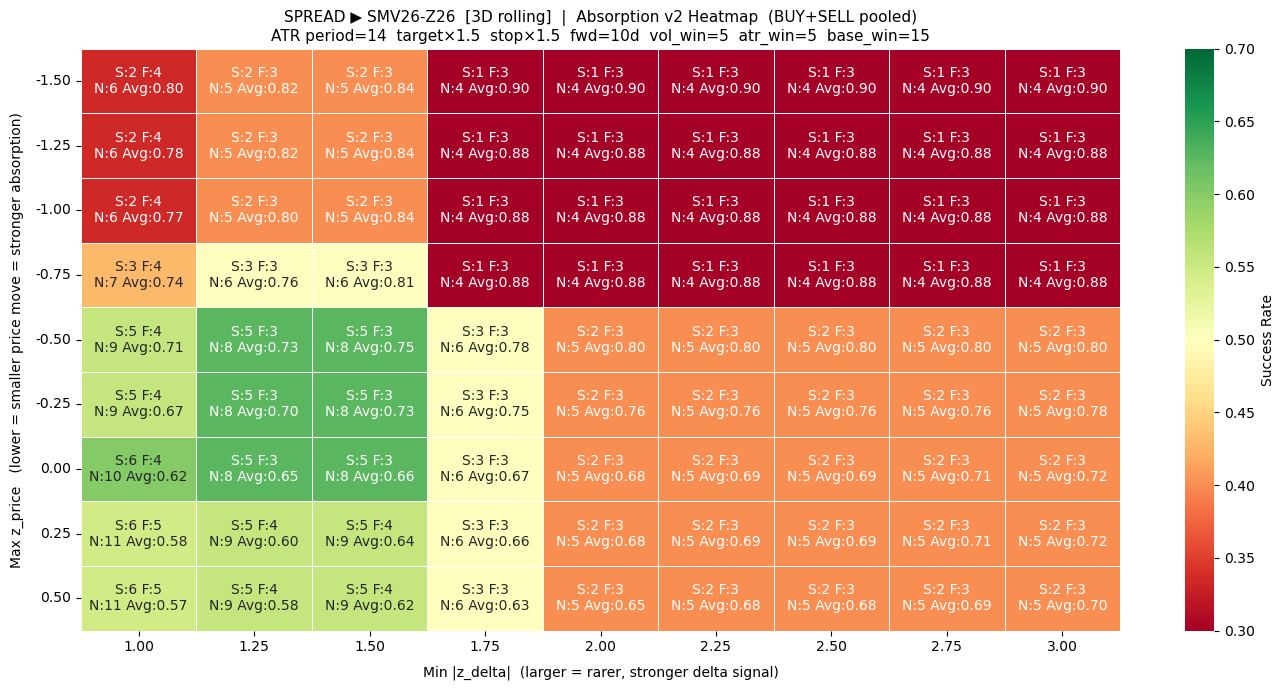

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


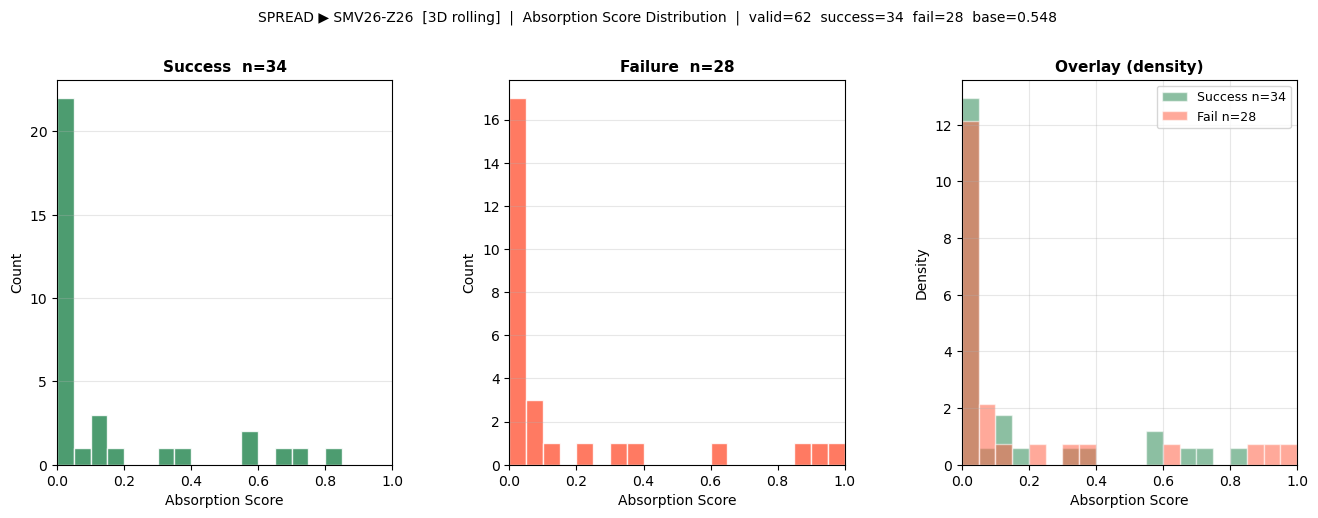


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMZ26-F27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 185


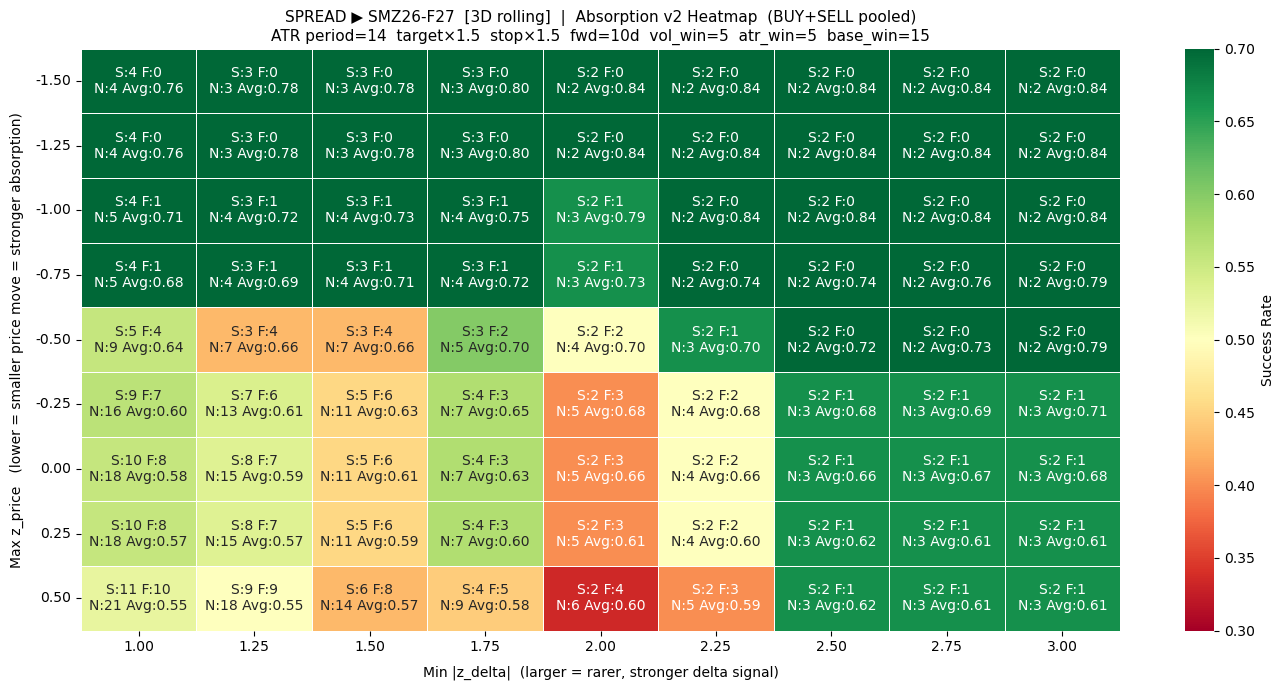

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


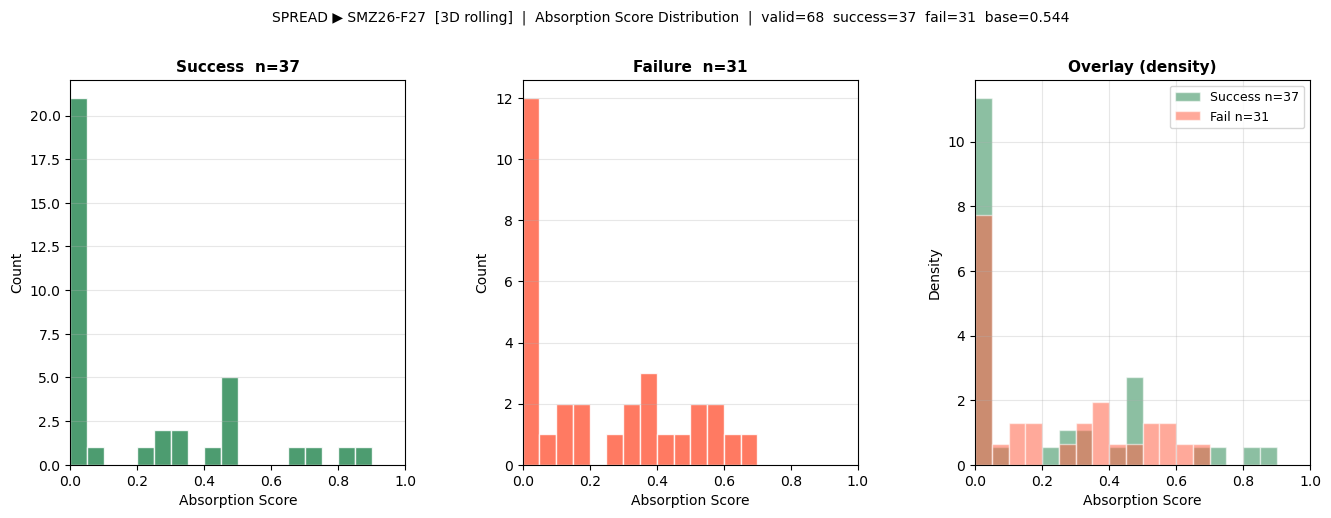


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMF27-H27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 184


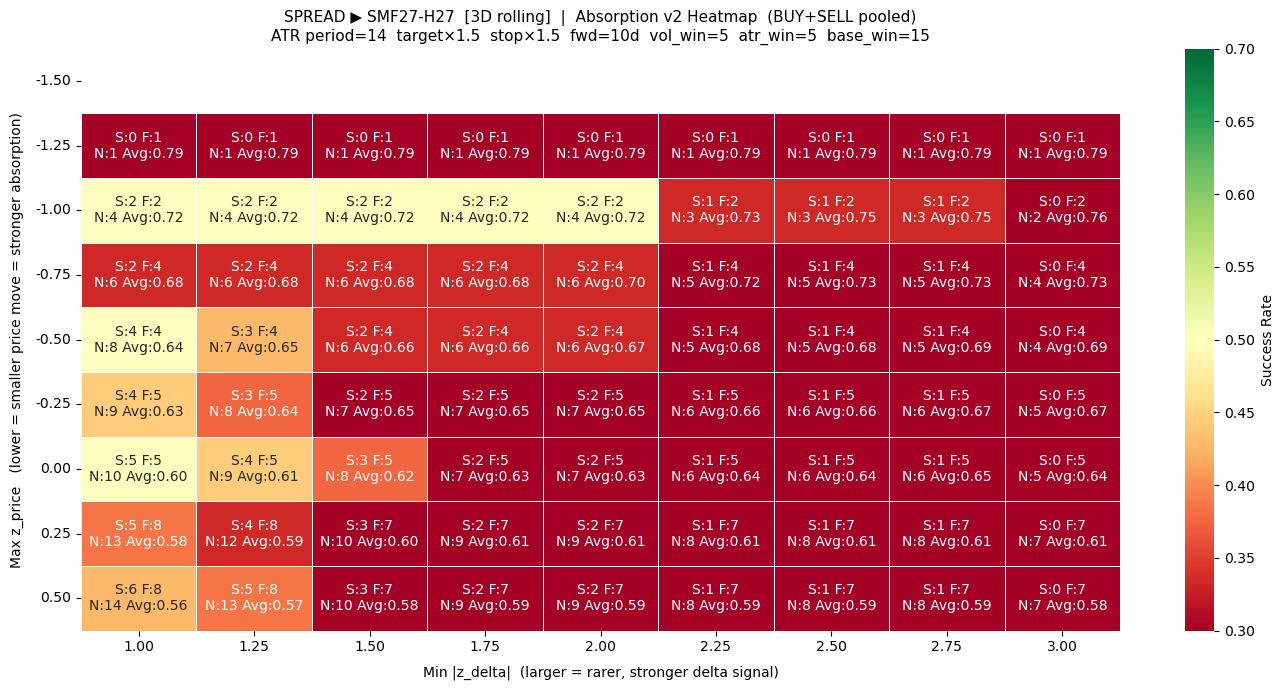

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


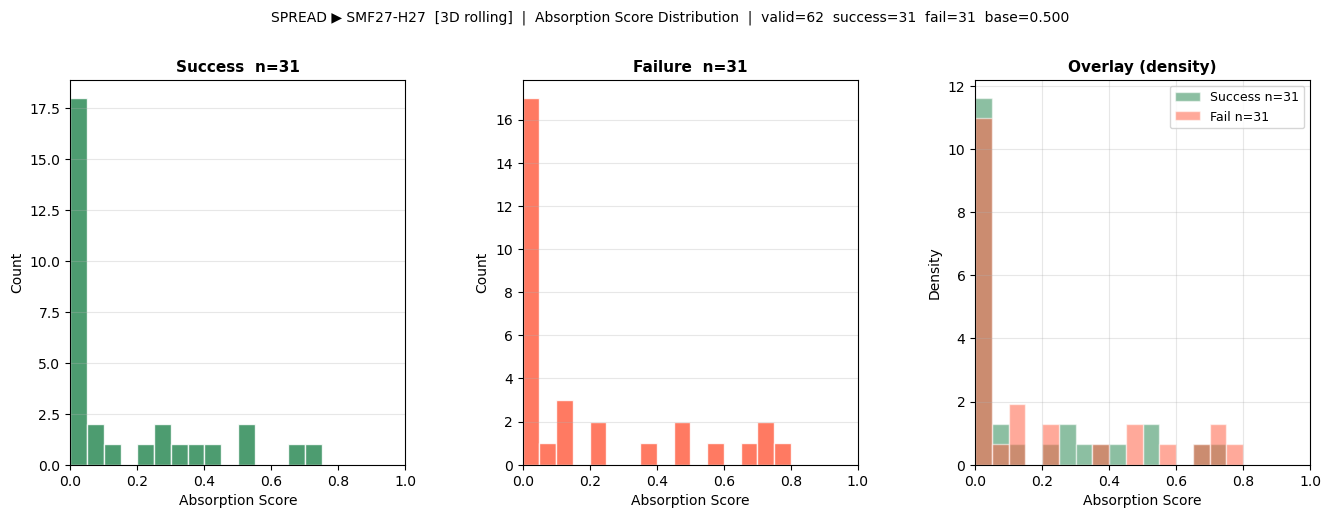


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMH27-K27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 180


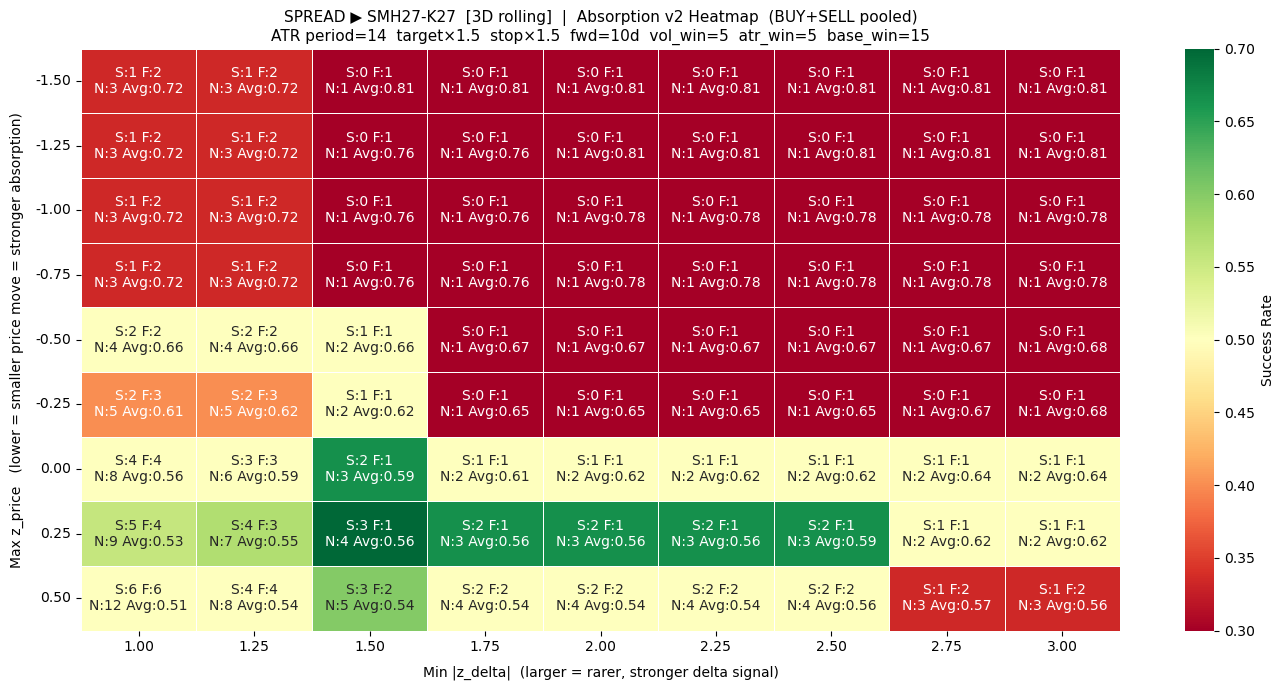

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


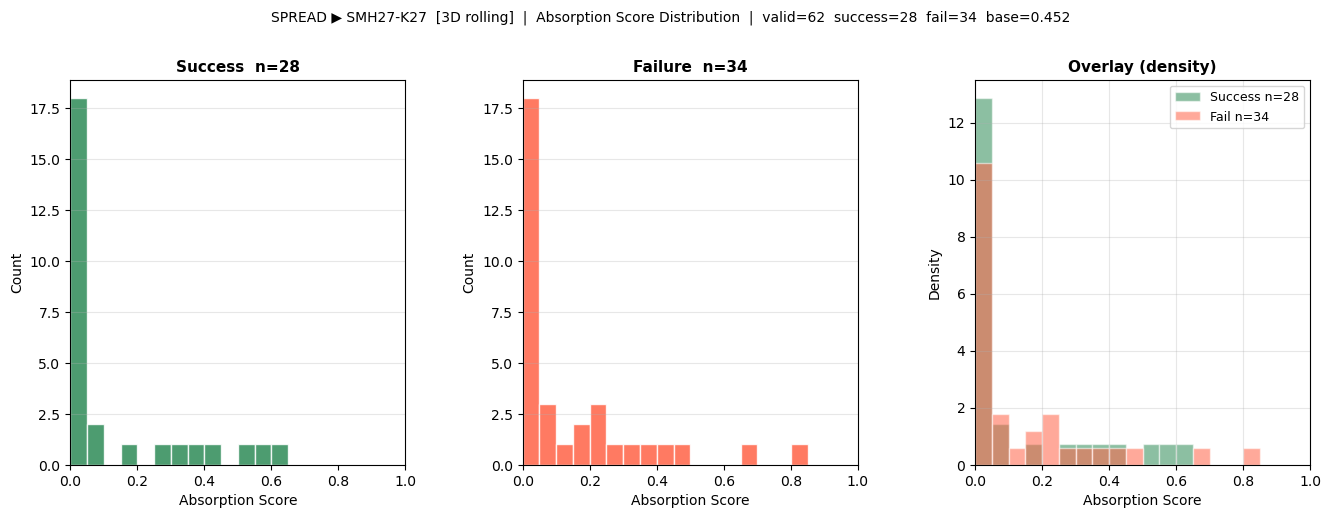


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMK27-N27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 172


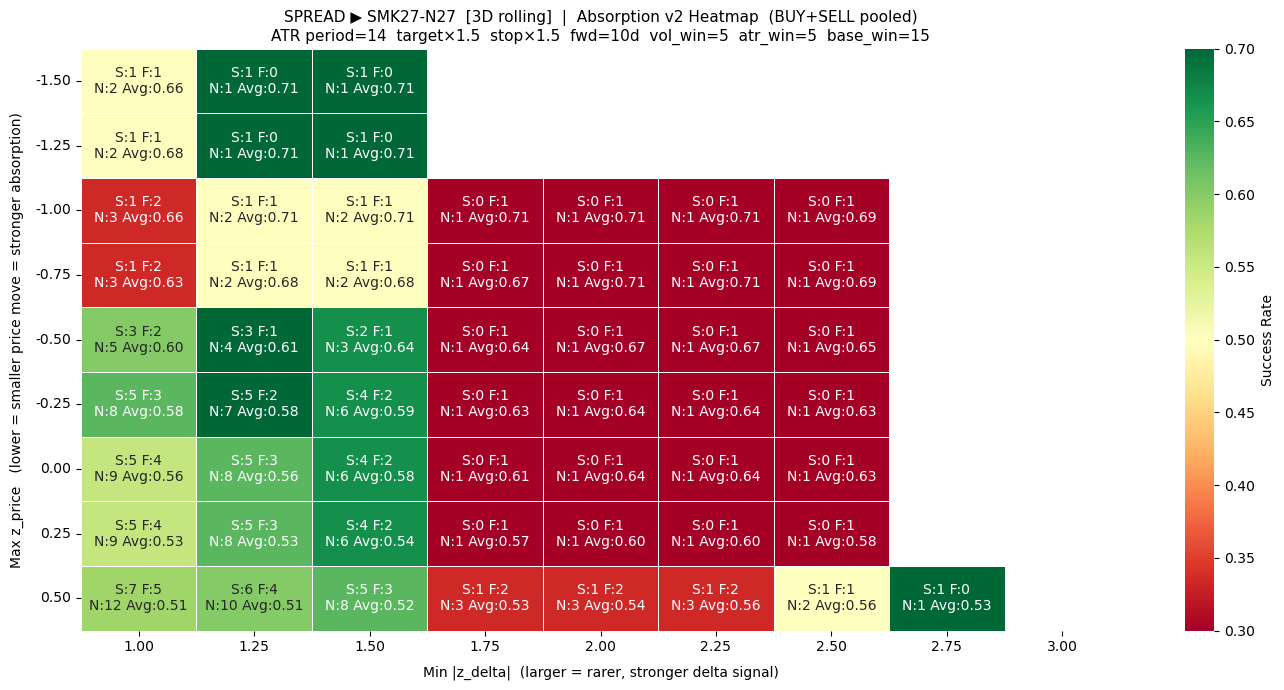

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


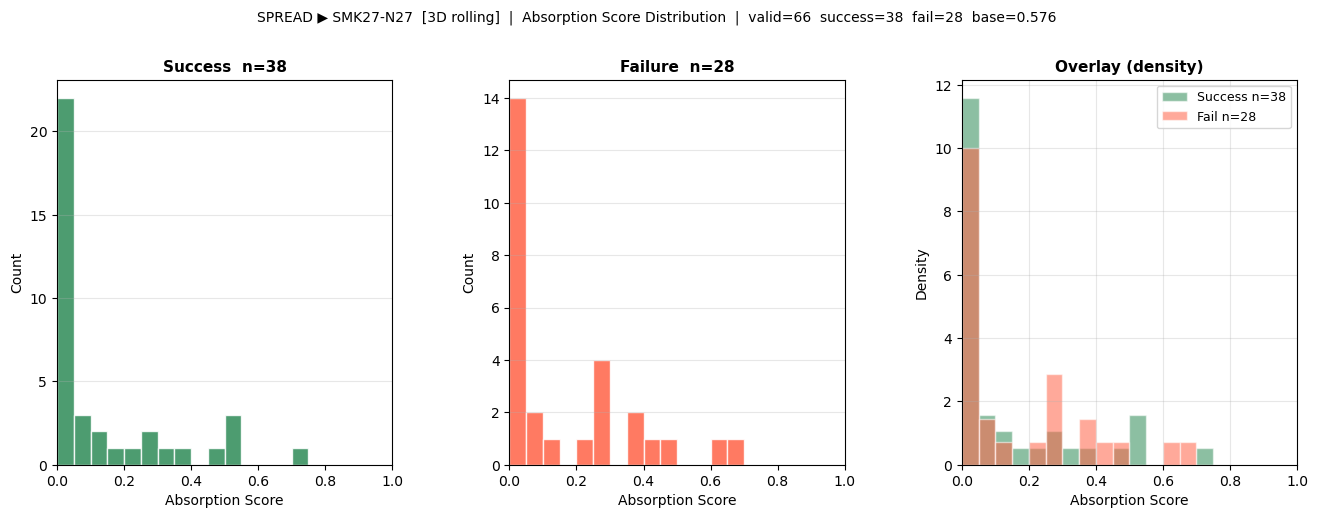


########################################################################
#  STRUCTURE : JUMBO  —  SM  [3D rolling]
########################################################################

──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-F27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 168


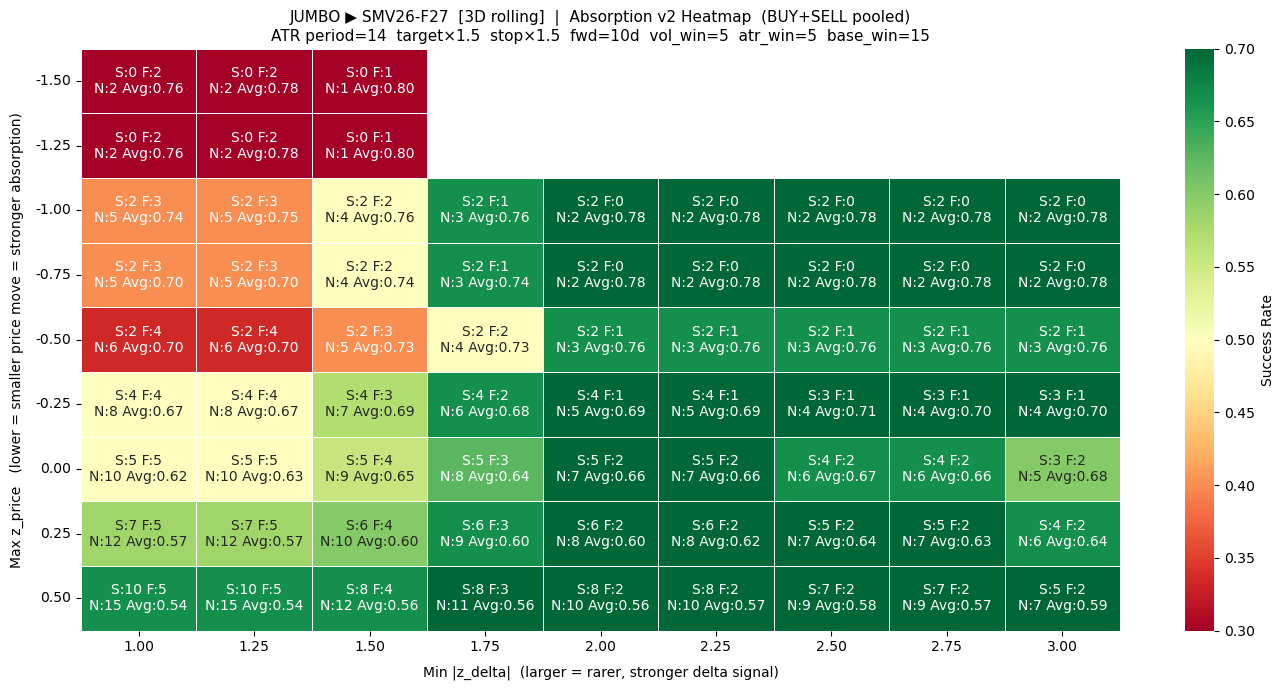

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


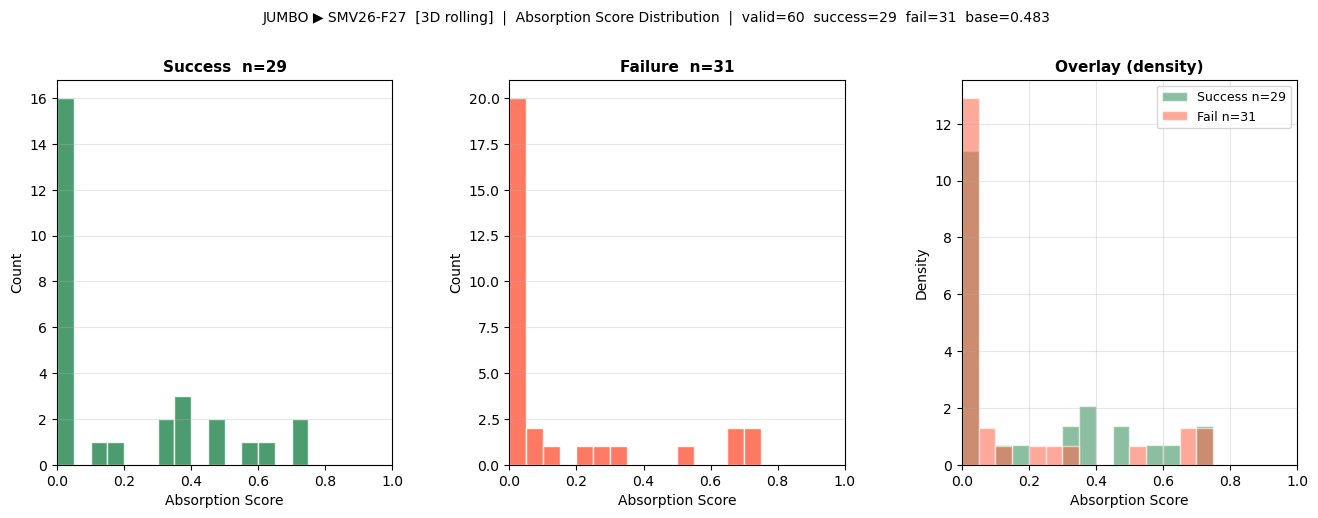


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-H27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 146


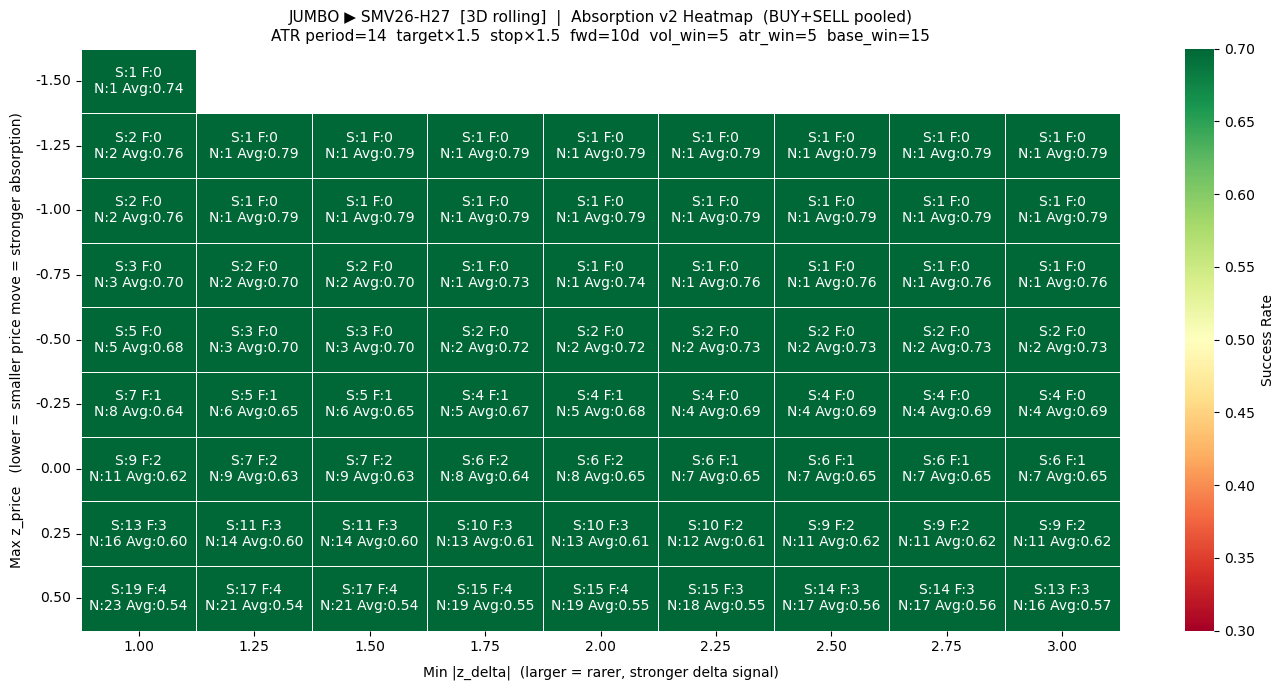

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


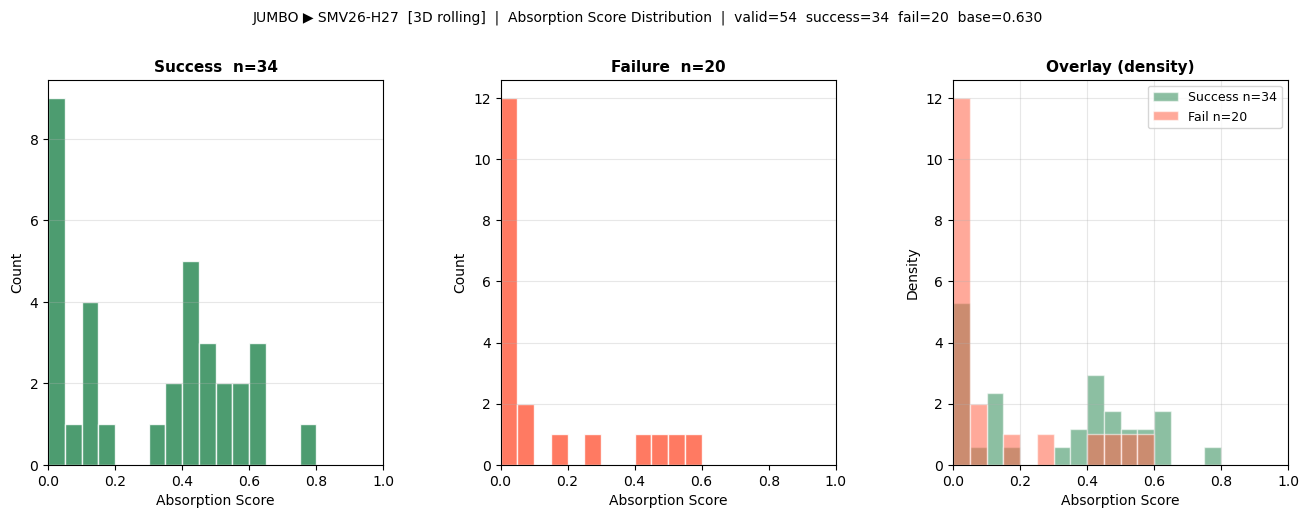


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-H27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 178


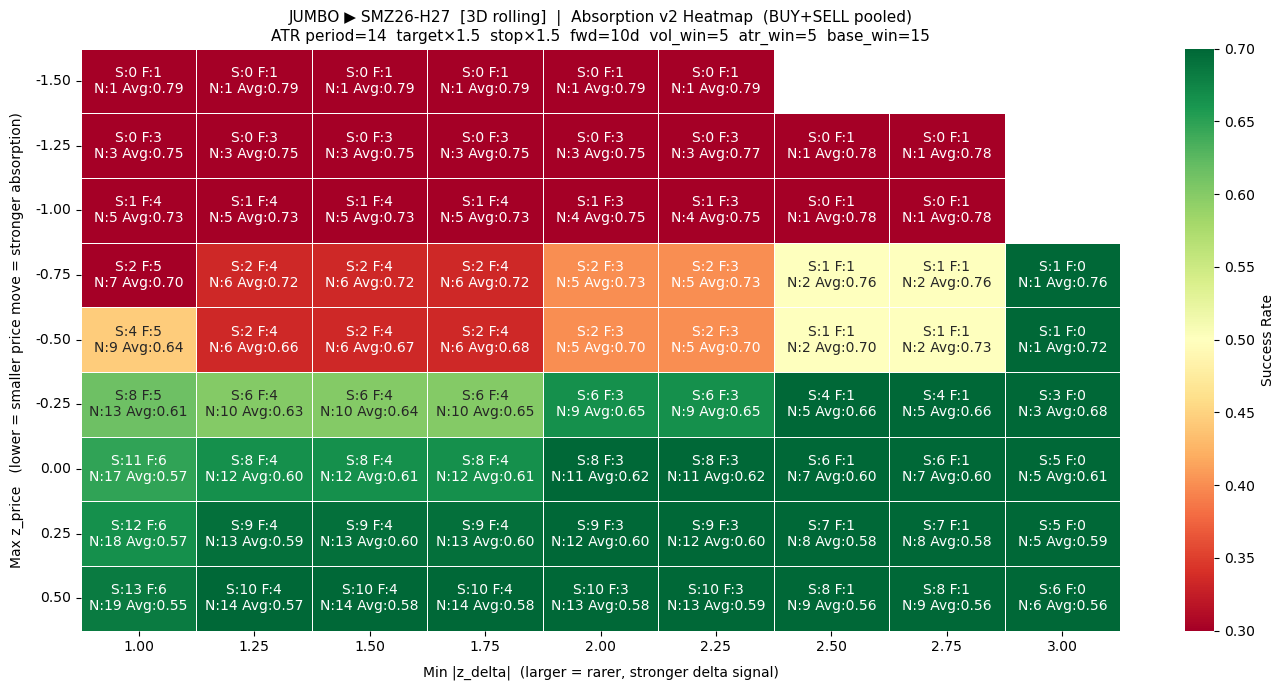

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


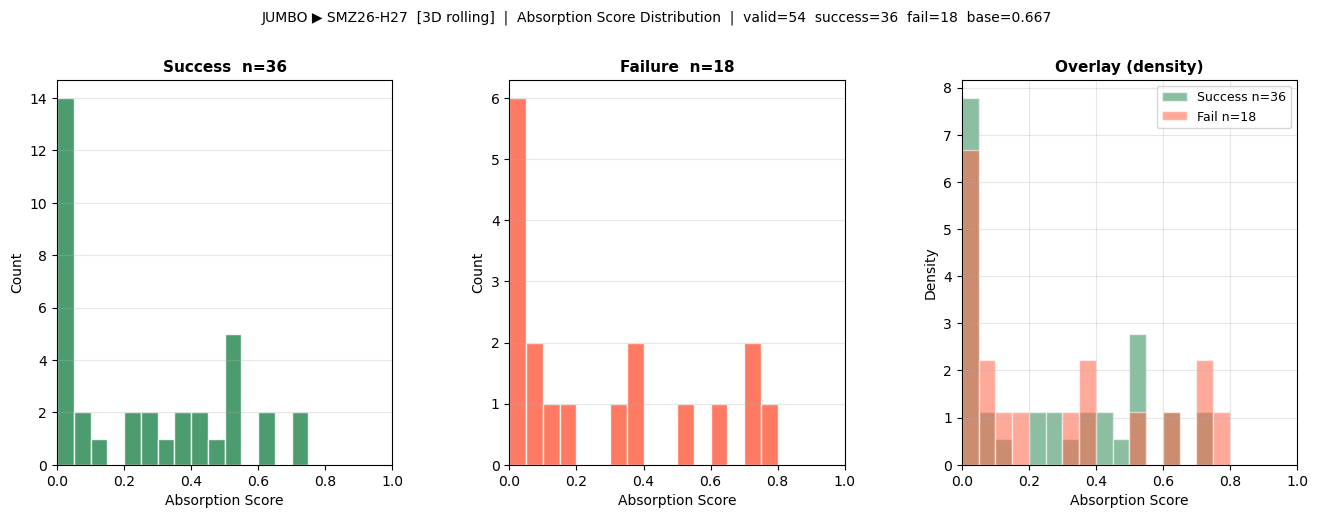


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-K27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 164


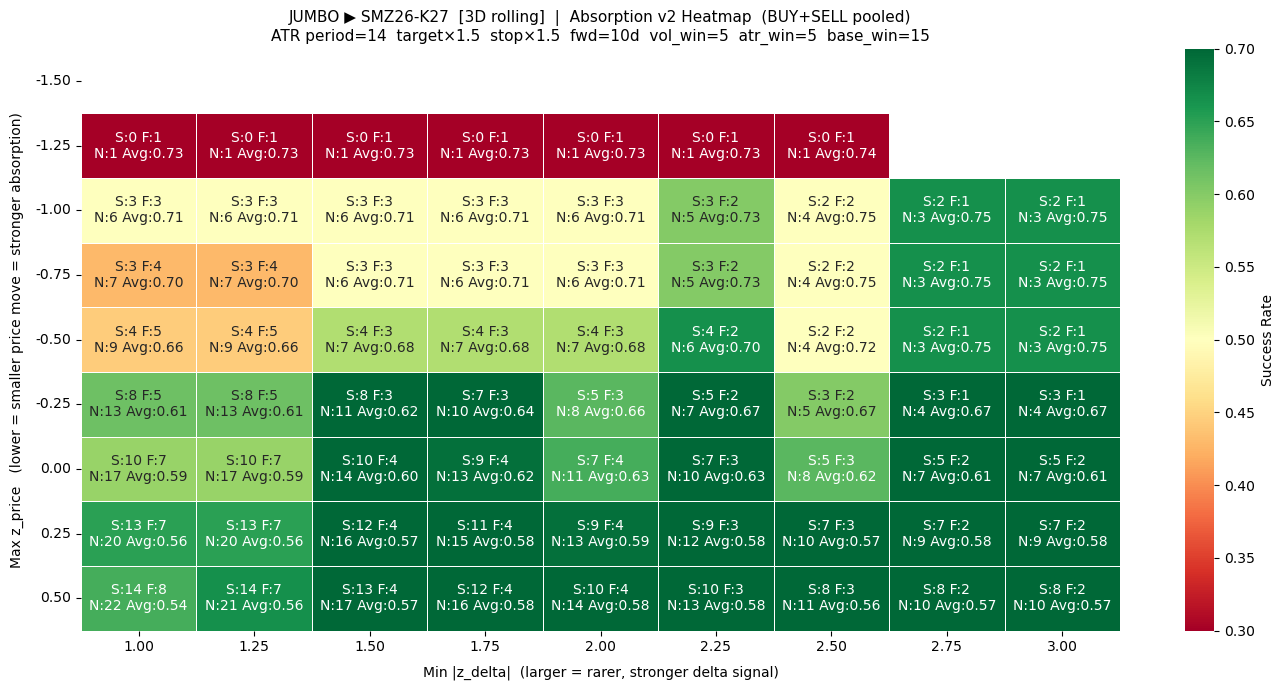

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


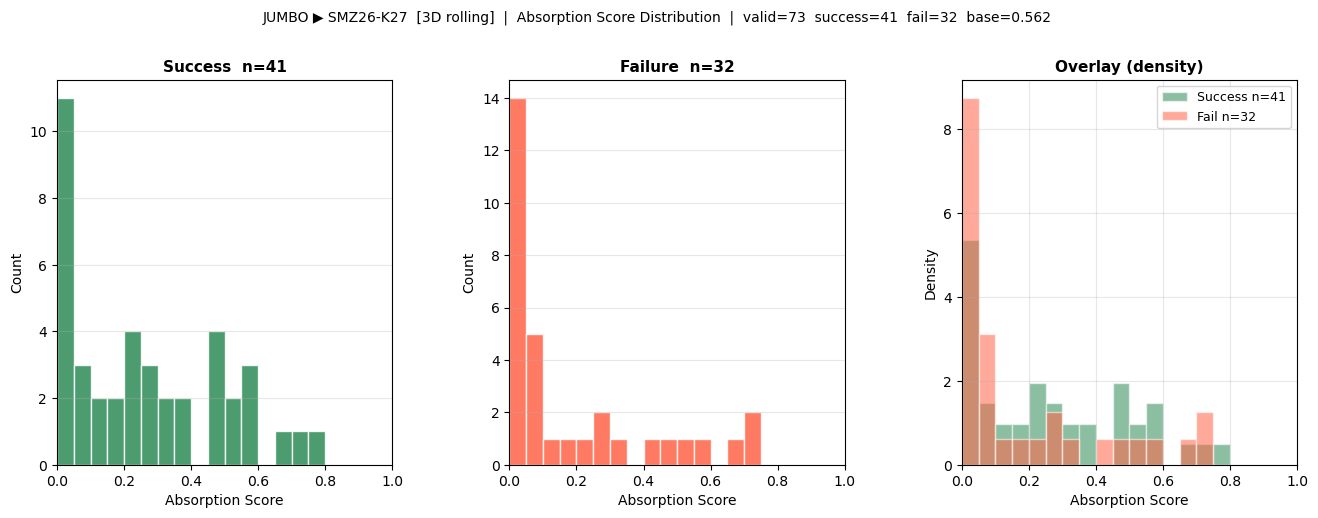


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMF27-K27  [1d  3D rolling]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 3D rolling
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  Bars fetched    : 145


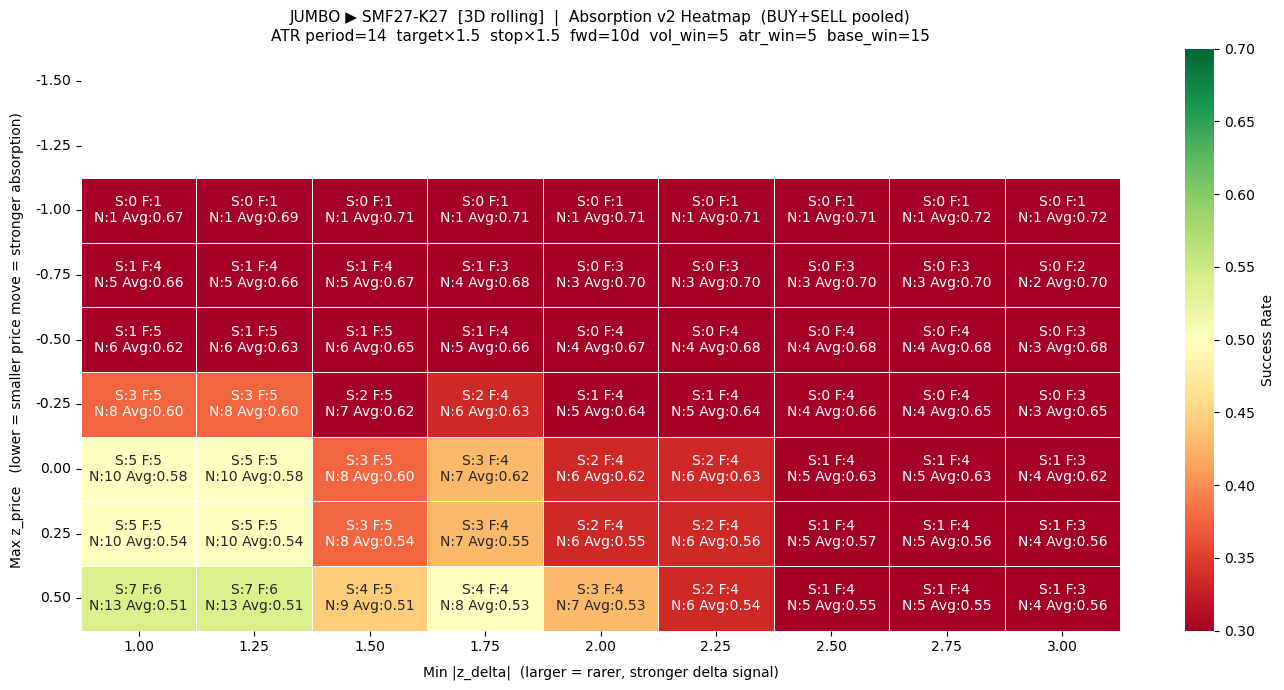

C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


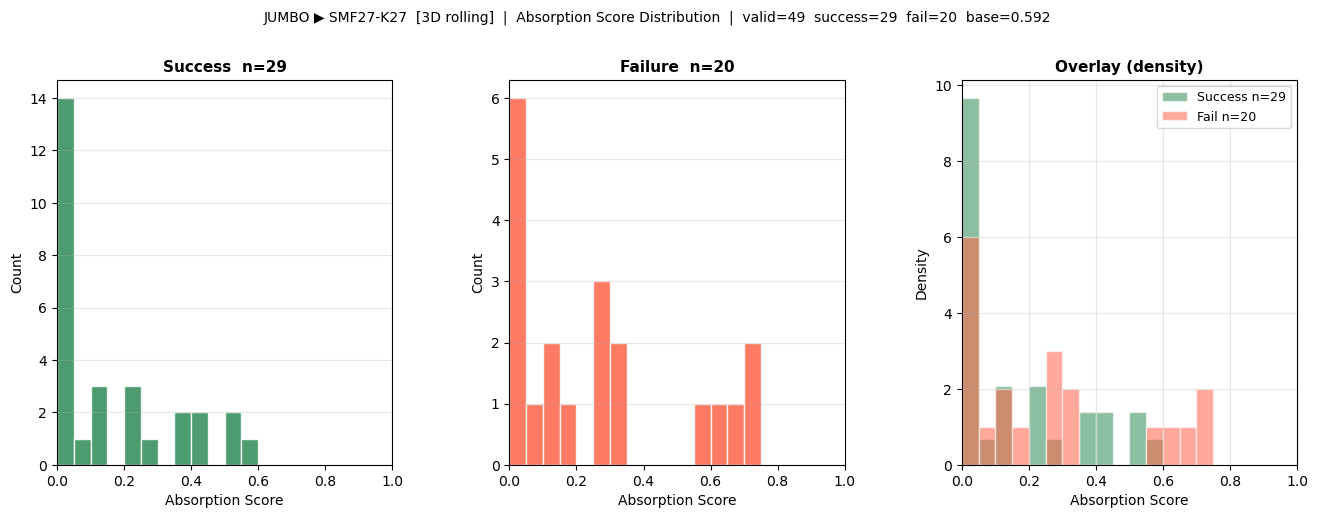

In [3]:
results_a = run_heatmap_analysis(
    product_code   = PRODUCT_CODE,
    months_back    = MONTHS_BACK,
    front_n        = FRONT_N,
    delta_z_grid   = DELTA_Z_GRID,
    price_z_grid   = PRICE_Z_GRID,
    combined_candle = COMBINED_CANDLE,   # ← this is all you change
    params         = V2_PARAMS,
    show_heatmap   = True,
    show_dist_plot = True,
)

## Cell B — Pooled Heatmap per Structure (Spread / Jumbo)

Same heatmap as Cell A but all instruments within each structure type are pooled into one matrix. Reduces per-instrument noise and gives a cleaner signal quality picture at the structure level.


########################################################################
#  POOLED HEATMAP — SPREAD  (SM)
########################################################################
  Loading SMV26-Z26...
  Loading SMZ26-F27...
  Loading SMF27-H27...
  Loading SMH27-K27...
  Loading SMK27-N27...


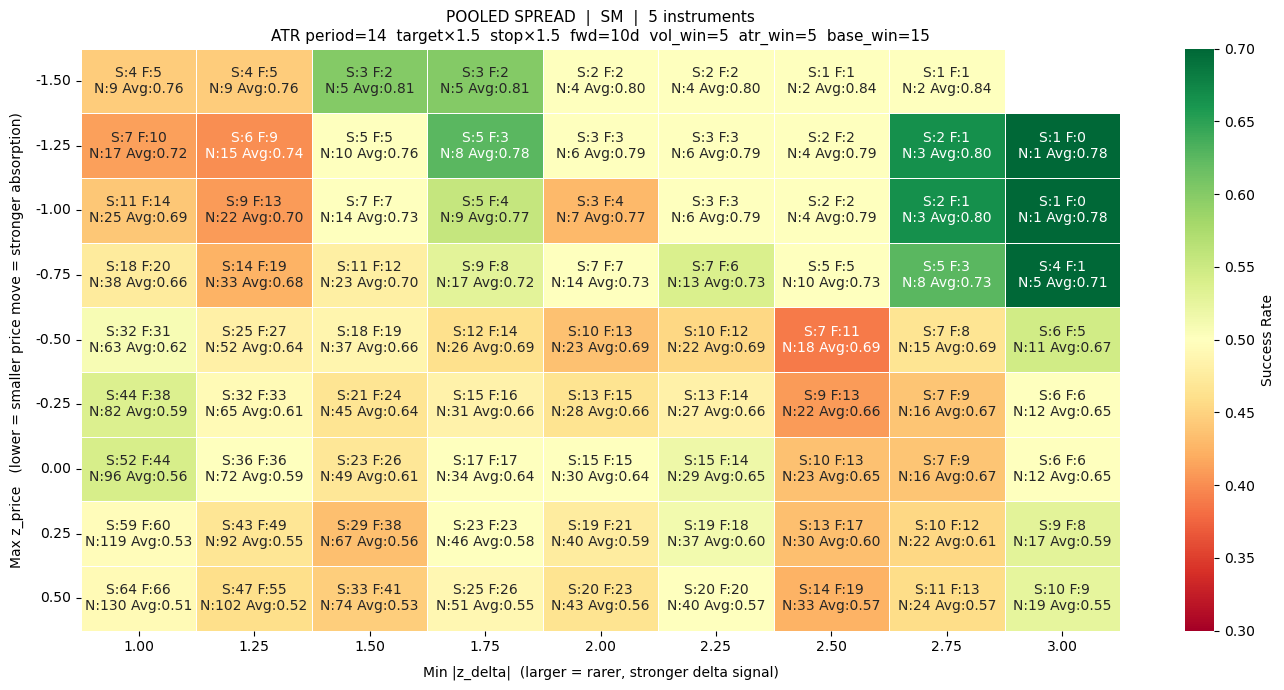


########################################################################
#  POOLED HEATMAP — JUMBO  (SM)
########################################################################
  Loading SMV26-F27...
  Loading SMV26-H27...
  Loading SMZ26-H27...
  Loading SMZ26-K27...
  Loading SMF27-K27...


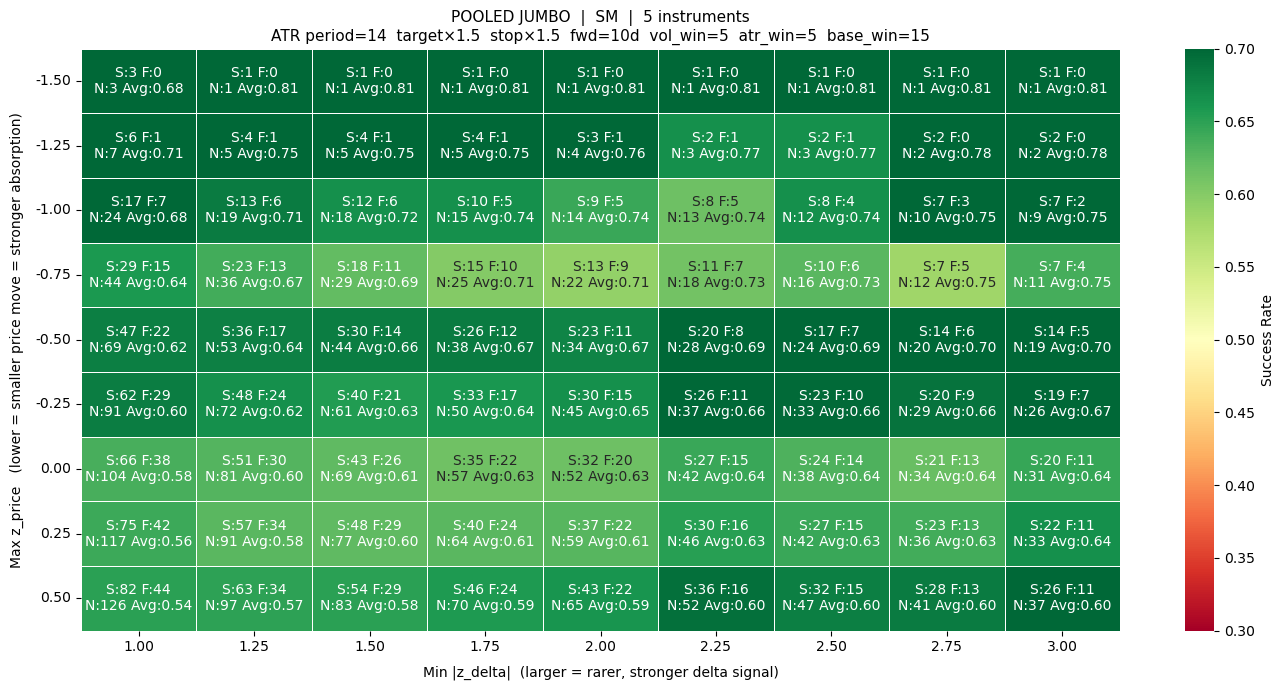

In [4]:
results_b = run_heatmap_by_structure(
    product_code   = PRODUCT_CODE,
    months_back    = MONTHS_BACK,
    front_n        = FRONT_N,
    delta_z_grid   = DELTA_Z_GRID,
    price_z_grid   = PRICE_Z_GRID,
    params         = V2_PARAMS,
    show_heatmap   = True,
    show_dist_plot = False,   # no per-instrument distributions in pooled mode
)

## Cell C — Absorption Score Threshold Sweep Table

Sweeps the **continuous `absorption_score`** (not the z-thresholds) and computes
Precision / Precision CI (bootstrap) / Recall / F1 / MCC / Lift at each cut-off.

Yellow rows = N < MIN_SIGNAL_COUNT (statistically unreliable).


########################################################################
#  STRUCTURE : SPREAD  —  SM  (threshold sweep)
########################################################################

──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMV26-Z26  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=88  valid outcomes=53  success_rate=0.547
  SELL  directional bars=81  valid outcomes=62  success_rate=0.419

  Threshold sweep  (base=0.478  PR-AUC=0.427)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,37,0.378,"[0.231,0.519]",0.255,0.304,-0.138,0.791,14,23,41,37,False
1,0.100,37,0.378,"[0.231,0.519]",0.255,0.304,-0.138,0.791,14,23,41,37,False
2,0.150,30,0.433,"[0.250,0.606]",0.236,0.306,-0.053,0.906,13,17,42,43,False
3,0.200,26,0.462,"[0.255,0.641]",0.218,0.296,-0.018,0.965,12,14,43,46,False
4,0.250,22,0.500,"[0.294,0.694]",0.200,0.286,0.021,1.045,11,11,44,49,False
5,0.300,17,0.471,"[0.231,0.696]",0.145,0.222,-0.006,0.984,8,9,47,51,False
6,0.350,16,0.438,"[0.222,0.667]",0.127,0.197,-0.033,0.915,7,9,48,51,False
7,0.400,14,0.500,"[0.235,0.786]",0.127,0.203,0.016,1.045,7,7,48,53,False
8,0.450,8,0.500,"[0.167,1.000]",0.073,0.127,0.012,1.045,4,4,51,56,False
9,0.500,7,0.571,"[0.200,1.000]",0.073,0.129,0.047,1.195,4,3,51,57,True


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


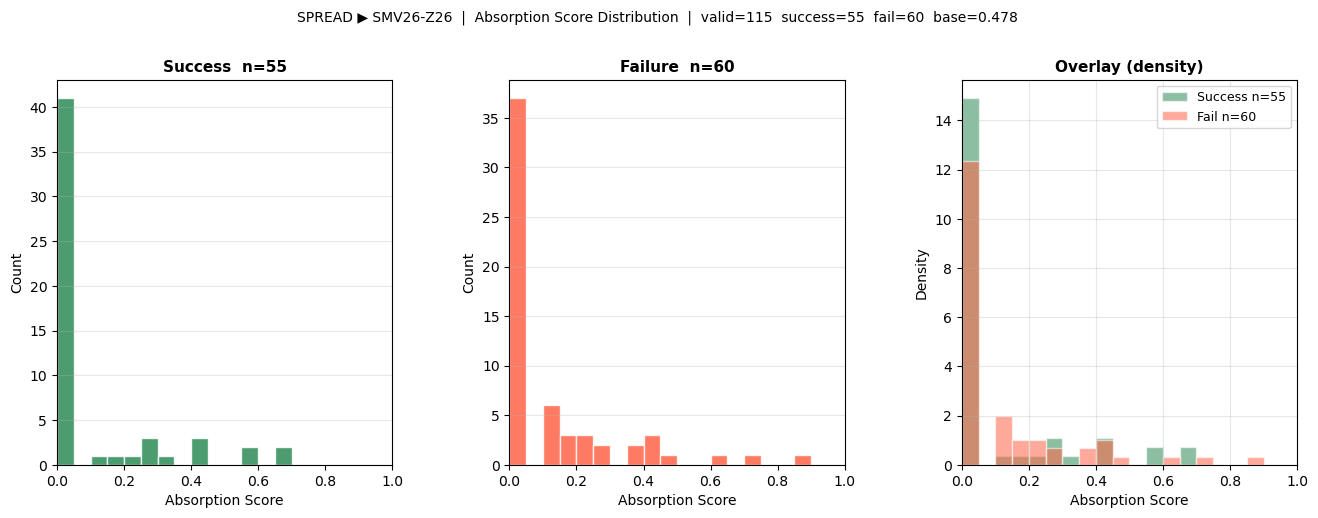


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMZ26-F27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=91  valid outcomes=77  success_rate=0.494
  SELL  directional bars=78  valid outcomes=64  success_rate=0.578

  Threshold sweep  (base=0.532  PR-AUC=0.544)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,48,0.542,"[0.388,0.667]",0.347,0.423,0.014,1.018,26,22,49,44,False
1,0.100,45,0.511,"[0.341,0.646]",0.307,0.383,-0.029,0.961,23,22,52,44,False
2,0.150,43,0.512,"[0.326,0.658]",0.293,0.373,-0.027,0.962,22,21,53,45,False
3,0.200,41,0.512,"[0.313,0.671]",0.280,0.362,-0.025,0.963,21,20,54,46,False
4,0.250,37,0.514,"[0.278,0.705]",0.253,0.339,-0.022,0.965,19,18,56,48,False
5,0.300,30,0.467,"[0.235,0.706]",0.187,0.267,-0.068,0.877,14,16,61,50,False
6,0.350,27,0.481,"[0.227,0.744]",0.173,0.255,-0.049,0.905,13,14,62,52,False
7,0.400,24,0.542,"[0.301,0.778]",0.173,0.263,0.009,1.018,13,11,62,55,False
8,0.450,18,0.556,"[0.279,0.833]",0.133,0.215,0.018,1.044,10,8,65,58,False
9,0.500,16,0.500,"[0.211,0.807]",0.107,0.176,-0.023,0.940,8,8,67,58,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


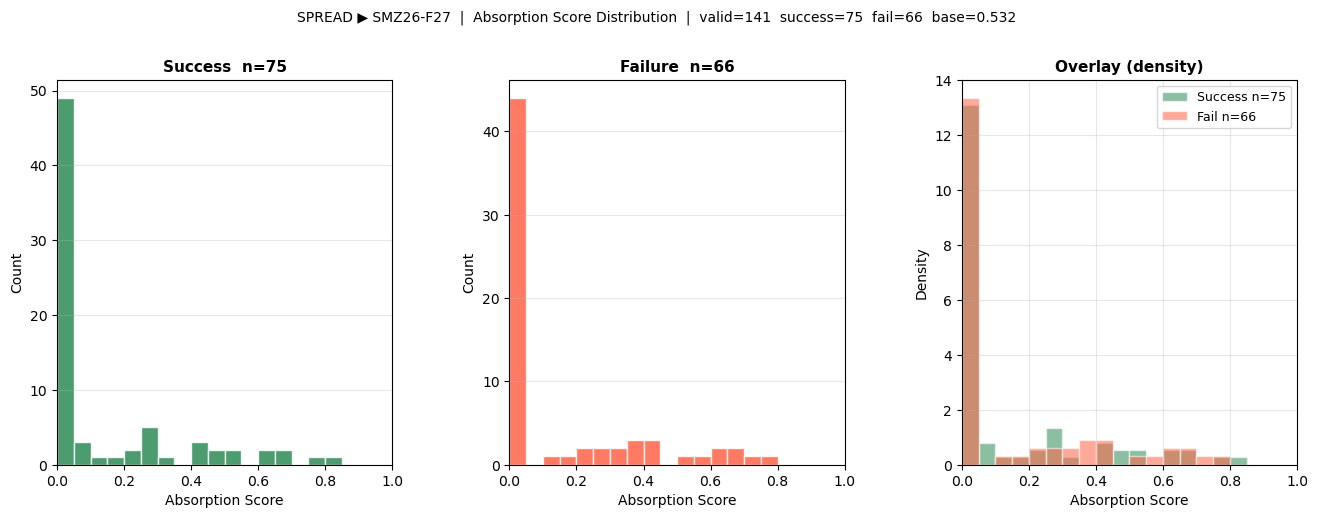


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMF27-H27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=79  valid outcomes=66  success_rate=0.409
  SELL  directional bars=84  valid outcomes=65  success_rate=0.677

  Threshold sweep  (base=0.542  PR-AUC=0.508)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,39,0.487,"[0.329,0.631]",0.268,0.345,-0.072,0.899,19,20,52,40,False
1,0.100,38,0.474,"[0.316,0.614]",0.254,0.330,-0.088,0.874,18,20,53,40,False
2,0.150,35,0.457,"[0.316,0.643]",0.225,0.302,-0.103,0.843,16,19,55,41,False
3,0.200,35,0.457,"[0.316,0.643]",0.225,0.302,-0.103,0.843,16,19,55,41,False
4,0.250,32,0.438,"[0.299,0.625]",0.197,0.272,-0.119,0.807,14,18,57,42,False
5,0.300,29,0.414,"[0.265,0.593]",0.169,0.240,-0.137,0.763,12,17,59,43,False
6,0.350,26,0.462,"[0.317,0.641]",0.169,0.247,-0.080,0.852,12,14,59,46,False
7,0.400,22,0.545,"[0.356,0.769]",0.169,0.258,0.003,1.006,12,10,59,50,False
8,0.450,17,0.529,"[0.333,0.750]",0.127,0.205,-0.010,0.977,9,8,62,52,False
9,0.500,15,0.467,"[0.200,0.725]",0.099,0.163,-0.054,0.861,7,8,64,52,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


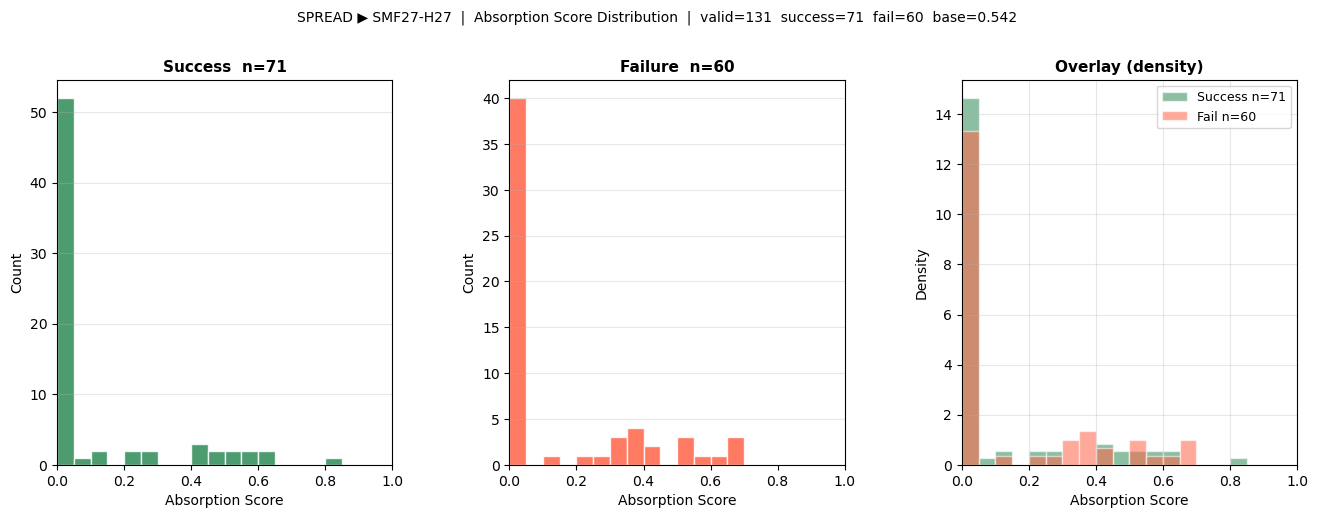


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMH27-K27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=86  valid outcomes=71  success_rate=0.380
  SELL  directional bars=78  valid outcomes=64  success_rate=0.578

  Threshold sweep  (base=0.474  PR-AUC=0.485)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,49,0.469,"[0.354,0.612]",0.359,0.407,-0.007,0.990,23,26,41,45,False
1,0.100,46,0.478,"[0.364,0.609]",0.344,0.400,0.006,1.009,22,24,42,47,False
2,0.150,43,0.465,"[0.357,0.604]",0.312,0.374,-0.012,0.981,20,23,44,48,False
3,0.200,39,0.487,"[0.372,0.632]",0.297,0.369,0.017,1.028,19,20,45,51,False
4,0.250,36,0.472,"[0.357,0.641]",0.266,0.340,-0.002,0.996,17,19,47,52,False
5,0.300,32,0.469,"[0.367,0.630]",0.234,0.312,-0.006,0.989,15,17,49,54,False
6,0.350,28,0.464,"[0.333,0.652]",0.203,0.283,-0.010,0.979,13,15,51,56,False
7,0.400,26,0.500,"[0.380,0.710]",0.203,0.289,0.025,1.055,13,13,51,58,False
8,0.450,20,0.550,"[0.372,0.786]",0.172,0.262,0.063,1.160,11,9,53,62,False
9,0.500,14,0.571,"[0.357,0.793]",0.125,0.205,0.066,1.205,8,6,56,65,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


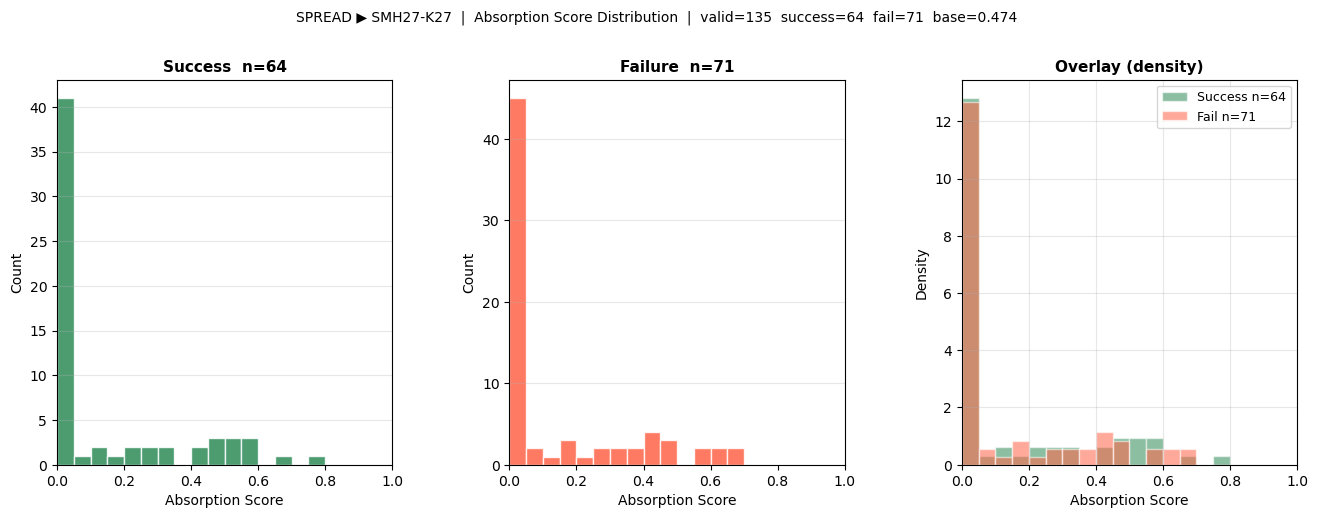


──────────────────────────────────────────────────────────────────────
  SPREAD  ▶  SMK27-N27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=72  valid outcomes=55  success_rate=0.564
  SELL  directional bars=84  valid outcomes=66  success_rate=0.591

  Threshold sweep  (base=0.579  PR-AUC=0.565)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,45,0.600,"[0.487,0.702]",0.386,0.470,0.033,1.037,27,18,43,33,False
1,0.100,43,0.581,"[0.459,0.685]",0.357,0.442,0.004,1.005,25,18,45,33,False
2,0.150,37,0.622,"[0.487,0.735]",0.329,0.430,0.058,1.075,23,14,47,37,False
3,0.200,33,0.606,"[0.468,0.750]",0.286,0.388,0.034,1.048,20,13,50,38,False
4,0.250,32,0.594,"[0.465,0.732]",0.271,0.373,0.019,1.026,19,13,51,38,False
5,0.300,28,0.571,"[0.417,0.742]",0.229,0.327,-0.008,0.988,16,12,54,39,False
6,0.350,26,0.577,"[0.431,0.746]",0.214,0.312,-0.002,0.997,15,11,55,40,False
7,0.400,24,0.542,"[0.399,0.708]",0.186,0.277,-0.037,0.936,13,11,57,40,False
8,0.450,21,0.524,"[0.389,0.700]",0.157,0.242,-0.051,0.905,11,10,59,41,False
9,0.500,12,0.417,"[0.160,0.667]",0.071,0.122,-0.109,0.720,5,7,65,44,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


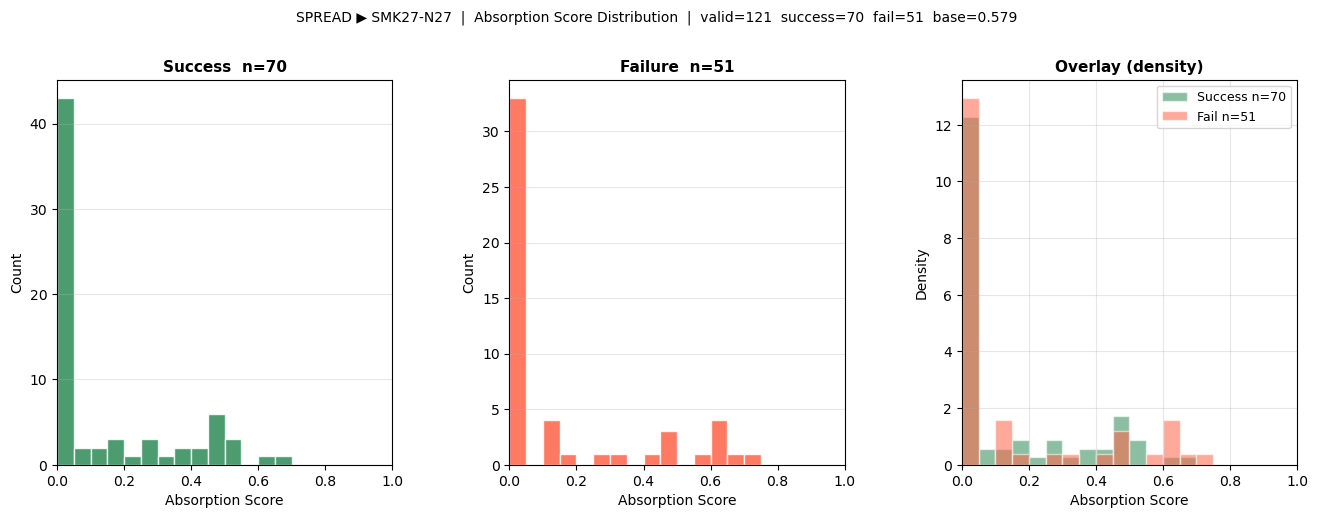


########################################################################
#  STRUCTURE : JUMBO  —  SM  (threshold sweep)
########################################################################

──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-F27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=74  valid outcomes=56  success_rate=0.607
  SELL  directional bars=78  valid outcomes=67  success_rate=0.403

  Threshold sweep  (base=0.496  PR-AUC=0.563)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,39,0.538,"[0.387,0.682]",0.344,0.420,0.058,1.086,21,18,40,44,False
1,0.100,36,0.500,"[0.329,0.656]",0.295,0.371,0.005,1.008,18,18,43,44,False
2,0.150,32,0.531,"[0.348,0.732]",0.279,0.366,0.042,1.071,17,15,44,47,False
3,0.200,29,0.552,"[0.344,0.746]",0.262,0.356,0.062,1.112,16,13,45,49,False
4,0.250,29,0.552,"[0.344,0.746]",0.262,0.356,0.062,1.112,16,13,45,49,False
5,0.300,26,0.615,"[0.396,0.824]",0.262,0.368,0.124,1.241,16,10,45,52,False
6,0.350,23,0.696,"[0.460,0.864]",0.262,0.381,0.192,1.403,16,7,45,55,False
7,0.400,19,0.632,"[0.375,0.833]",0.197,0.300,0.116,1.274,12,7,49,55,False
8,0.450,17,0.647,"[0.400,0.875]",0.180,0.282,0.121,1.305,11,6,50,56,False
9,0.500,11,0.545,"[0.200,0.909]",0.098,0.167,0.031,1.100,6,5,55,57,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


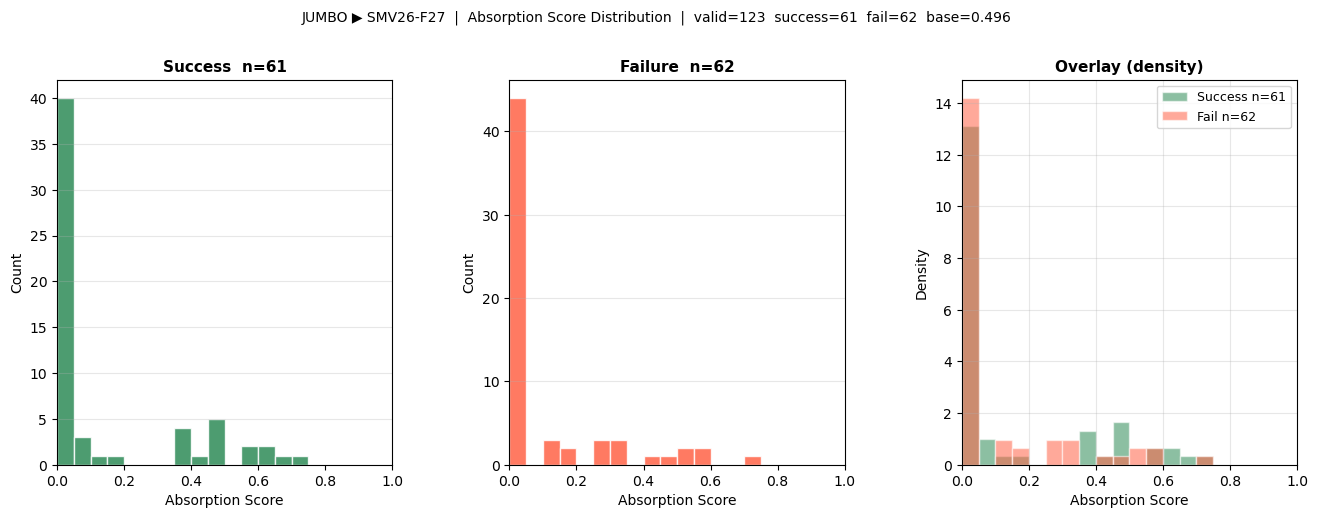


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMV26-H27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=64  valid outcomes=53  success_rate=0.585
  SELL  directional bars=66  valid outcomes=54  success_rate=0.481

  Threshold sweep  (base=0.533  PR-AUC=0.584)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,39,0.615,"[0.444,0.773]",0.421,0.500,0.125,1.155,24,15,33,35,False
1,0.100,37,0.622,"[0.450,0.789]",0.404,0.489,0.130,1.167,23,14,34,36,False
2,0.150,35,0.657,"[0.487,0.818]",0.404,0.500,0.174,1.234,23,12,34,38,False
3,0.200,34,0.676,"[0.500,0.839]",0.404,0.505,0.197,1.270,23,11,34,39,False
4,0.250,29,0.690,"[0.500,0.862]",0.351,0.465,0.192,1.295,20,9,37,41,False
5,0.300,26,0.731,"[0.561,0.875]",0.333,0.458,0.225,1.372,19,7,38,43,False
6,0.350,26,0.731,"[0.561,0.875]",0.333,0.458,0.225,1.372,19,7,38,43,False
7,0.400,20,0.650,"[0.477,0.846]",0.228,0.338,0.113,1.220,13,7,44,43,False
8,0.450,18,0.611,"[0.400,0.833]",0.193,0.293,0.071,1.147,11,7,46,43,False
9,0.500,13,0.615,"[0.312,0.905]",0.140,0.229,0.062,1.155,8,5,49,45,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


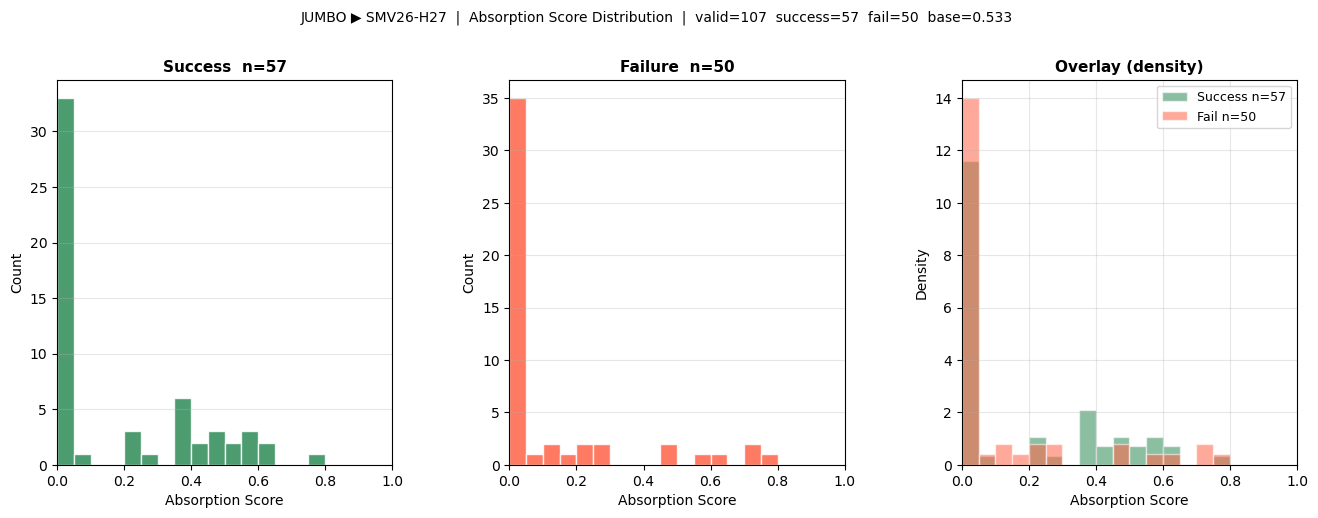


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-H27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=79  valid outcomes=64  success_rate=0.516
  SELL  directional bars=83  valid outcomes=65  success_rate=0.692

  Threshold sweep  (base=0.605  PR-AUC=0.639)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,44,0.591,"[0.476,0.704]",0.333,0.426,-0.020,0.977,26,18,52,33,False
1,0.100,42,0.595,"[0.477,0.711]",0.321,0.417,-0.013,0.984,25,17,53,34,False
2,0.150,41,0.585,"[0.455,0.703]",0.308,0.403,-0.027,0.968,24,17,54,34,False
3,0.200,36,0.583,"[0.434,0.682]",0.269,0.368,-0.027,0.965,21,15,57,36,False
4,0.250,31,0.613,"[0.436,0.770]",0.244,0.349,0.009,1.014,19,12,59,39,False
5,0.300,27,0.630,"[0.439,0.796]",0.218,0.324,0.026,1.041,17,10,61,41,False
6,0.350,24,0.667,"[0.478,0.830]",0.205,0.314,0.061,1.103,16,8,62,43,False
7,0.400,22,0.682,"[0.466,0.861]",0.192,0.300,0.072,1.128,15,7,63,44,False
8,0.450,18,0.778,"[0.579,1.000]",0.179,0.292,0.143,1.286,14,4,64,47,False
9,0.500,14,0.714,"[0.489,1.000]",0.128,0.217,0.078,1.181,10,4,68,47,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


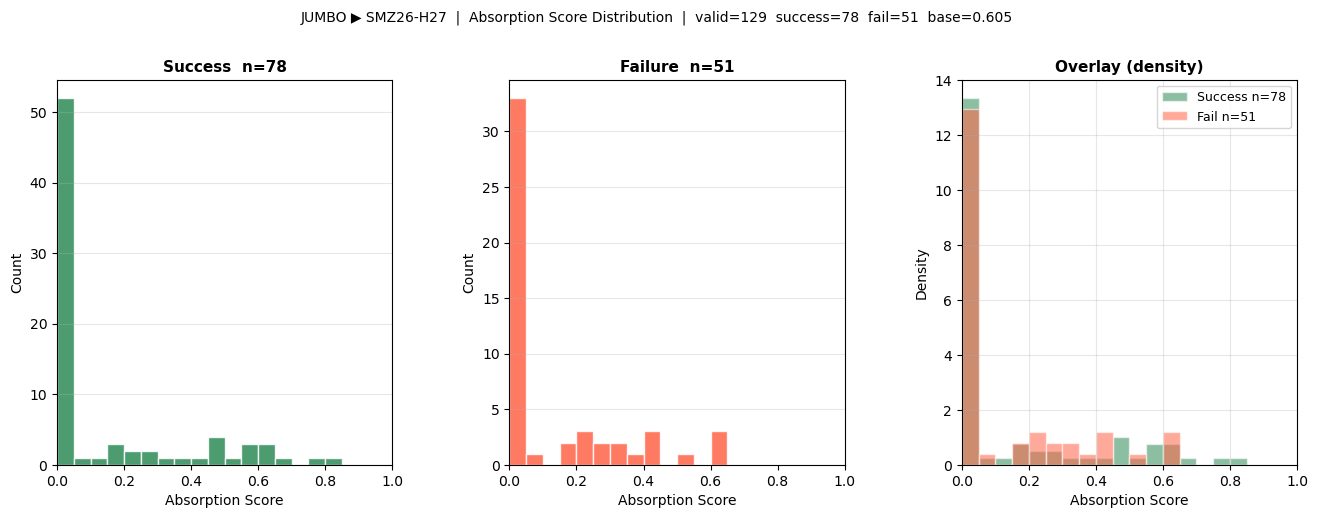


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMZ26-K27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=75  valid outcomes=67  success_rate=0.522
  SELL  directional bars=73  valid outcomes=54  success_rate=0.722

  Threshold sweep  (base=0.612  PR-AUC=0.731)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,39,0.718,"[0.581,0.857]",0.378,0.496,0.151,1.174,28,11,46,36,False
1,0.100,36,0.750,"[0.616,0.906]",0.365,0.491,0.185,1.226,27,9,47,38,False
2,0.150,35,0.743,"[0.600,0.901]",0.351,0.477,0.172,1.215,26,9,48,38,False
3,0.200,34,0.735,"[0.600,0.901]",0.338,0.463,0.159,1.202,25,9,49,38,False
4,0.250,31,0.742,"[0.600,0.912]",0.311,0.438,0.157,1.213,23,8,51,39,False
5,0.300,29,0.759,"[0.623,0.927]",0.297,0.427,0.169,1.240,22,7,52,40,False
6,0.350,25,0.720,"[0.550,0.913]",0.243,0.364,0.114,1.177,18,7,56,40,False
7,0.400,22,0.773,"[0.630,1.000]",0.230,0.354,0.156,1.264,17,5,57,42,False
8,0.450,22,0.773,"[0.630,1.000]",0.230,0.354,0.156,1.264,17,5,57,42,False
9,0.500,20,0.800,"[0.650,1.000]",0.216,0.340,0.172,1.308,16,4,58,43,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


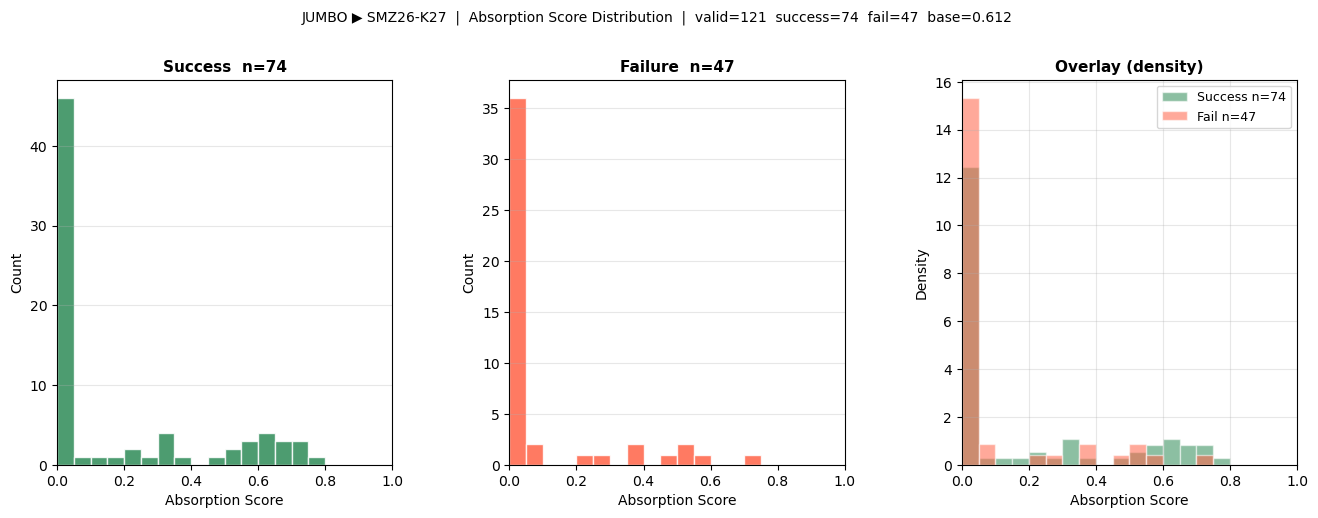


──────────────────────────────────────────────────────────────────────
  JUMBO  ▶  SMF27-K27  [1d  1D]  (SM)
──────────────────────────────────────────────────────────────────────
  Data            : 2026-01-28 → 2026-09-28  (0 bars)
  Candle          : 1D
  Tick size       : 0.1
  volume_window   : 5
  atr_window      : 5
  baseline_window : 15
  atr_period      : 14
  target×stop     : 1.5 / 1.5
  forward_days    : 10
──────────────────────────────────────────────────────────────────────
  BUY   directional bars=67  valid outcomes=56  success_rate=0.411
  SELL  directional bars=62  valid outcomes=52  success_rate=0.538

  Threshold sweep  (base=0.472  PR-AUC=0.523)


,Score Thresh,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.050,40,0.525,"[0.287,0.721]",0.412,0.462,0.081,1.112,21,19,30,38,False
1,0.100,36,0.528,"[0.297,0.708]",0.373,0.437,0.079,1.118,19,17,32,40,False
2,0.150,36,0.528,"[0.297,0.708]",0.373,0.437,0.079,1.118,19,17,32,40,False
3,0.200,32,0.531,"[0.305,0.719]",0.333,0.410,0.077,1.125,17,15,34,42,False
4,0.250,31,0.516,"[0.293,0.700]",0.314,0.390,0.056,1.093,16,15,35,42,False
5,0.300,28,0.500,"[0.274,0.679]",0.275,0.354,0.033,1.059,14,14,37,43,False
6,0.350,27,0.519,"[0.288,0.700]",0.275,0.359,0.054,1.098,14,13,37,44,False
7,0.400,25,0.520,"[0.288,0.700]",0.255,0.342,0.053,1.101,13,12,38,45,False
8,0.450,25,0.520,"[0.288,0.700]",0.255,0.342,0.053,1.101,13,12,38,45,False
9,0.500,22,0.545,"[0.289,0.756]",0.235,0.329,0.074,1.155,12,10,39,47,False


C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\finding_threshold\absorption_v2_threshold.py:377: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


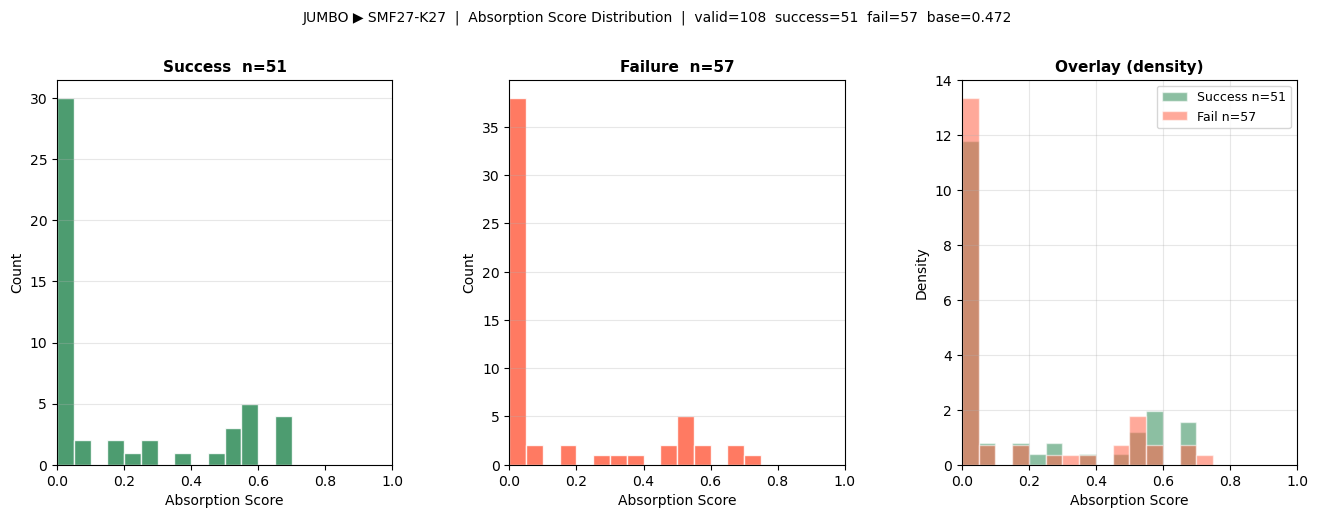

In [5]:
results_c = run_threshold_sweep(
    product_code     = PRODUCT_CODE,
    months_back      = MONTHS_BACK,
    front_n          = FRONT_N,
    score_grid       = SCORE_GRID,
    params           = V2_PARAMS,
    min_signal_count = MIN_SIGNAL_COUNT,
    n_bootstrap      = N_BOOTSTRAP,
    random_seed      = RANDOM_SEED,
    show_plots       = True,
)

## Optional — Quick result inspection

After running any of the cells above you can inspect individual instrument results here.

In [6]:
# Example: print sweep table for first instrument in Cell C results
if results_c:
    first_inst = next(iter(results_c))
    r = results_c[first_inst]
    print(f"Instrument : {first_inst}")
    print(f"Base rate  : {r['base_rate']:.3f}")
    print(f"PR-AUC     : {r['pr_auc']:.3f}")
    print()
    display(r['sweep_table'].to_string(index=False))

Instrument : SMV26-Z26
Base rate  : 0.478
PR-AUC     : 0.427



' Score Thresh  N  Precision   Prec CI 95%   Recall       F1       MCC     Lift  TP  FP  FN  TN  Low N\n         0.05 37   0.378378 [0.231,0.519] 0.254545 0.304348 -0.137716 0.791155  14  23  41  37  False\n         0.10 37   0.378378 [0.231,0.519] 0.254545 0.304348 -0.137716 0.791155  14  23  41  37  False\n         0.15 30   0.433333 [0.250,0.606] 0.236364 0.305882 -0.053432 0.906061  13  17  42  43  False\n         0.20 26   0.461538 [0.255,0.641] 0.218182 0.296296 -0.018094 0.965035  12  14  43  46  False\n         0.25 22   0.500000 [0.294,0.694] 0.200000 0.285714  0.021167 1.045455  11  11  44  49  False\n         0.30 17   0.470588 [0.231,0.696] 0.145455 0.222222 -0.006397 0.983957   8   9  47  51  False\n         0.35 16   0.437500 [0.222,0.667] 0.127273 0.197183 -0.032804 0.914773   7   9  48  51  False\n         0.40 14   0.500000 [0.235,0.786] 0.127273 0.202899  0.016203 1.045455   7   7  48  53  False\n         0.45  8   0.500000 [0.167,1.000] 0.072727 0.126984  0.011900 1.